# Diabetes Health Indicators dataset: binary classification

**Task.** Predict whether a person has diabetes from health indicators collected by survey.

**Dataset.** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset (the copy used here is the one provided on Moodle).  
**Characteristics given in the assignment.** about 250,000 entries, 21 features, unbalanced classes.

This notebook applies the workflow implemented in `ml_workflow.py` to this dataset, shows the results and comments on them. It contains no machine-learning logic of its own: every step is a call to a function of the module. The second notebook of the project follows the same structure on the other dataset.

## Setup

Imports, configuration of the dataset and software environment.

In [2]:
# Reload ml_workflow automatically whenever the file is edited.
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Project root = first parent folder containing src/ml_workflow.py
# (works whether Jupyter starts in notebooks/ or at the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ml_workflow.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import ml_workflow as mlw

In [4]:
# Dataset
DATASET_NAME = "DHI"
DATA_PATH = ROOT / "data" / "dhi" / "diabetes_binary_health_indicators_BRFSS2015.csv"
TARGET_COLUMN = "Diabetes_binary"

# Reproducibility
RANDOM_STATE = mlw.RANDOM_STATE

# Display
pd.set_option("display.max_columns", None)

In [5]:
# TODO: record the software environment that produced the results.
mlw.get_environment_info()

{'python': '3.12.10',
 'numpy': '2.5.4',
 'pandas': '3.1.1',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2'}

## 1. Import the dataset

Load the file and separate the features from the target.

In [6]:
# TODO: load the dataset.
X, y = mlw.load_dataset(DATASET_NAME, DATA_PATH, TARGET_COLUMN)

## 2. Clean and pre-process

Understand the data, clean it, and decide how it will be pre-processed.

### 2.1 Exploration

Size, feature types, missing values, class balance and correlations. This is where the specific difficulties of the dataset are identified.

#### Taille et nature des variables

In [ ]:
print(f"{X.shape[0]} rows, {X.shape[1]} features")
feature_types = mlw.describe_feature_types(X)
display(feature_types["kind"].value_counts())
display(feature_types.round(2))

253680 rows, 21 features


kind
binary        14
ordinal        4
continuous     3
Name: count, dtype: int64

,kind,n_unique,min,max,zeros_%,skewness
HighBP,binary,2,0.0,1.0,57.10,0.29
HighChol,binary,2,0.0,1.0,57.59,0.31
CholCheck,binary,2,0.0,1.0,3.73,-4.88
BMI,continuous,84,12.0,98.0,0.00,2.12
Smoker,binary,2,0.0,1.0,55.68,0.23
Stroke,binary,2,0.0,1.0,95.94,4.66
HeartDiseaseorAttack,binary,2,0.0,1.0,90.58,2.78
PhysActivity,binary,2,0.0,1.0,24.35,-1.20
Fruits,binary,2,0.0,1.0,36.57,-0.56
Veggies,binary,2,0.0,1.0,18.86,-1.59


**Commentaires.** 253 680 personnes décrites par 21 variables : 14 variables **binaires** (`HighBP`, `Smoker`...), 4 **ordinales** (`GenHlth` 1–5, `Age` 1–13 par tranches, `Education` 1–6, `Income` 1–8) et 3 **quasi continues** (`BMI` 12–98, `MentHlth` et `PhysHlth` en nombre de jours sur 30). 

→ les échelles vont de 0–1 à 12–98 : Une standardisation serait bien.

#### Répartition des classes

,count,proportion
Diabetes_binary,,
0.0,218334,0.860667
1.0,35346,0.139333


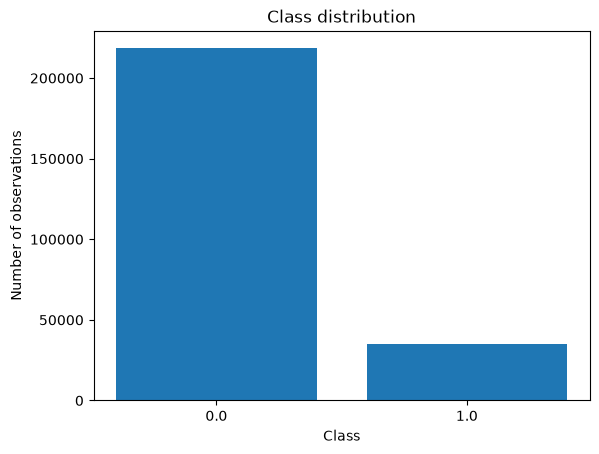

In [ ]:
# Distribution du dataset
display(mlw.get_class_distribution(y))
mlw.plot_class_distribution(y)
plt.show()

**Commentaires.** les classes sont **déséquilibrées** : un modèle qui prédit toujours 0 aurait déjà 86 % d'accuracy. On doit donc choisir une autre metric que l'accuracy (ROC AUC, F1 ...). Le split doit être **stratifié**.

#### Corrélations entre variables

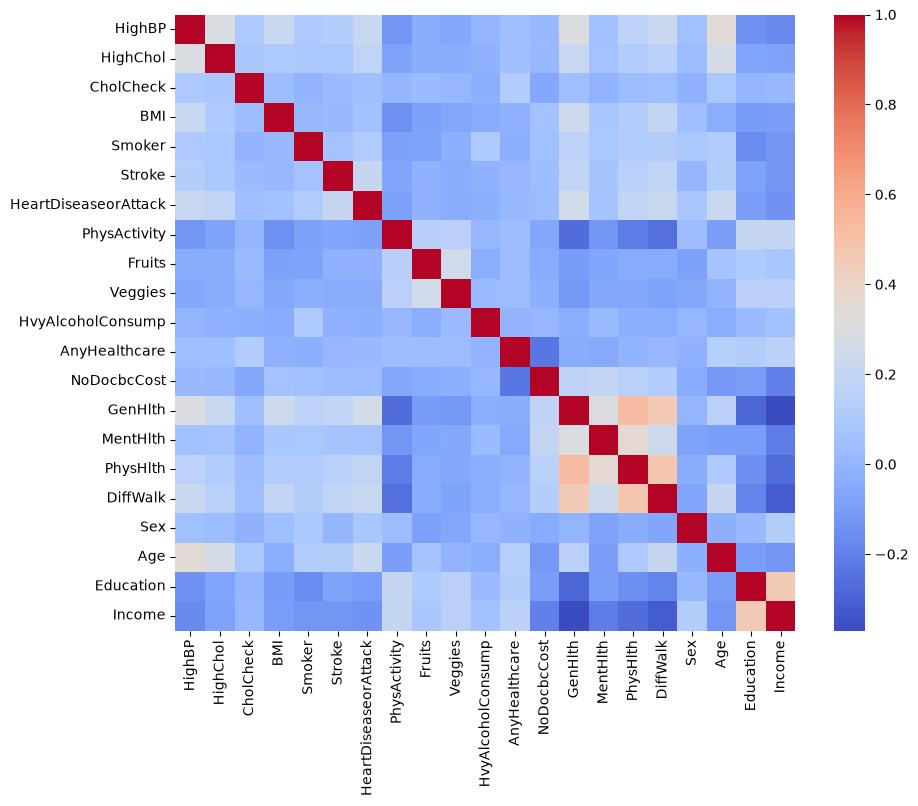

,feature_1,feature_2,abs_corr
0,GenHlth,PhysHlth,0.52
1,PhysHlth,DiffWalk,0.48
2,GenHlth,DiffWalk,0.46
3,Education,Income,0.45


In [ ]:
# Matrice de corrélation
fig, ax = plt.subplots(figsize=(14, 12) if X.shape[1] > 30 else (10, 8))
mlw.plot_correlation_matrix(X, ax=ax)
plt.show()

display(mlw.get_correlated_pairs(X, threshold=0.4).round(2))

**Commentaires.** On n'a pas une grande corrélation (<0.7). On peut dire que les variables apportent donc chacune une information **assez différente**.

#### Lien entre les variables et la cible

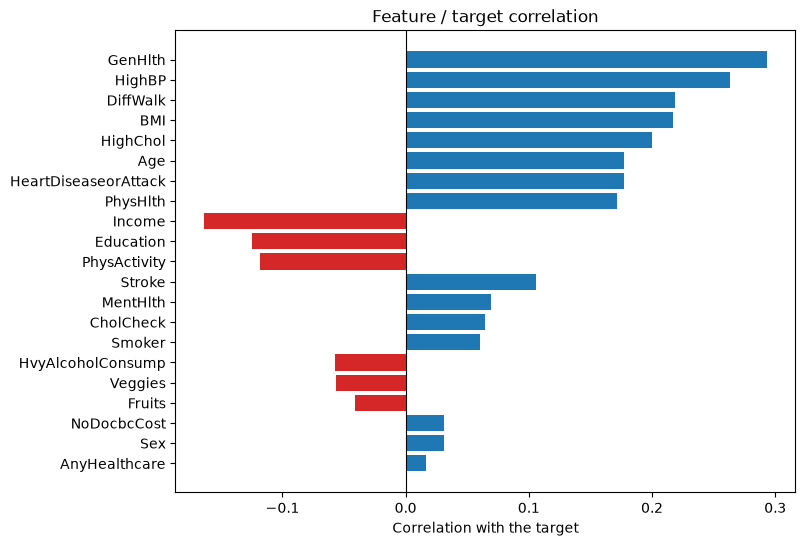

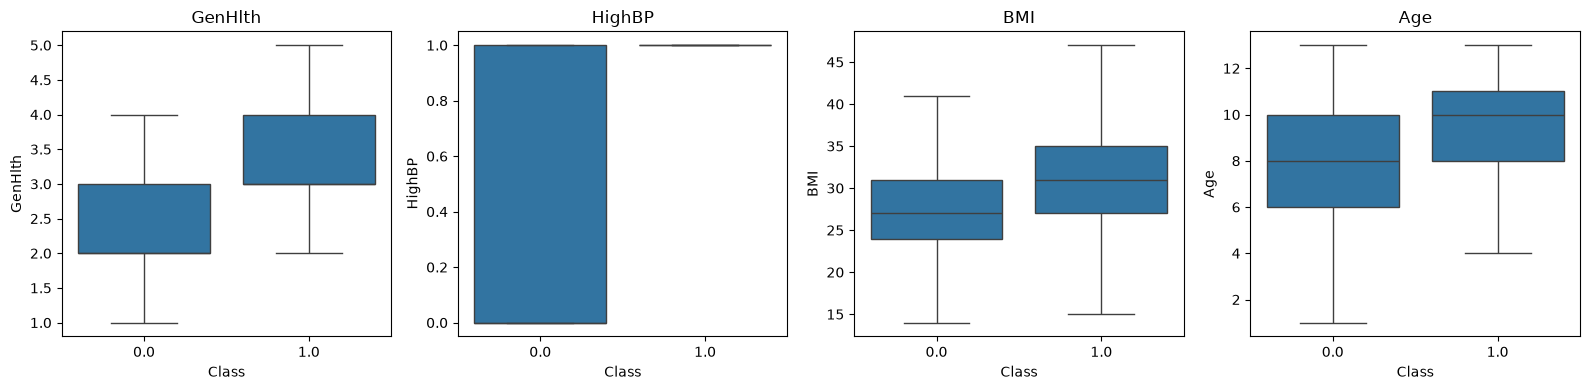

In [ ]:
# corrélation linéaire et son sens
fig, ax = plt.subplots(figsize=(8, 12) if X.shape[1] > 30 else (8, 6))
mlw.plot_target_correlation(X, y, ax=ax)
plt.show()

# Distribution de quelques features discriminantes dans chaque classe
FEATURES_TO_PLOT = ["GenHlth", "HighBP", "BMI", "Age"]
fig, axes = plt.subplots(1, len(FEATURES_TO_PLOT), figsize=(4 * len(FEATURES_TO_PLOT), 4))
for feature, ax in zip(FEATURES_TO_PLOT, axes):
    mlw.plot_feature_by_class(X, y, feature, ax=ax)
plt.tight_layout()
plt.show()

**Commentaires.** Les variables les plus liées au diabète sont la santé générale perçue (`GenHlth`), l'hypertension (`HighBP`), les difficultés à marcher, l'IMC (`BMI`), le cholestérol et l'âge (tout a fait normal et logique). Les boxplots montrent des distributions décalées entre les deux classes mais qui **se chevauchent beaucoup**. Le revenu, l'éducation et l'activité physique sont corrélés négativement. `Sex`, `AnyHealthcare`, `NoDocbcCost`, `Fruits` ou `Veggies` n'ont presque aucun lien avec la cible.

**Synthèse des choix justifiés par l'exploration.**

| Constat | Choix |
|---|---|
| ≈ 10 % de lignes identiques, attendues vu le type de données | doublons conservés |
| échelles de 0–1 à 12–98 | standardisation |
| 86 % / 14 % | split stratifié (3), métrique adaptée au déséquilibre (4.4) |
| corrélations entre variables modérées | PCA probablement peu utile (4.1) |

### 2.2 Cleaning

Operations that learn nothing from the data (type conversion, duplicate rows, rows without a label), so they can safely run before the split.

In [9]:
n_before = len(X)
X, y = mlw.clean_dataset(X, y, drop_duplicates=False)
print(f"{n_before - len(X)} rows removed, {len(X)} left")
print("Identical rows kept:", int(X.assign(target=y).duplicated().sum()))
display(mlw.get_class_distribution(y))

0 rows removed, 253680 left
Identical rows kept: 24206


,count,proportion
Diabetes_binary,,
0.0,218334,0.860667
1.0,35346,0.139333


### 2.3 Pre-processing choices

Replacement of missing values (mean or median), centring and normalisation, and PCA.

These steps learn statistics from the data. To keep the test set unseen, they are only *chosen* here: they are *fitted* later, on the training set alone, as steps of the model pipeline (section 4).

In [10]:
# Au cas ou il manque des données (median car il y a des valeurs binaires)
IMPUTE_STRATEGY = "median"

## 3. Split into training and test sets

Stratified split with a fixed seed. The test set is not used again before section 5.

In [11]:
# Stratified 80/20 split (TEST_SIZE in ml_workflow) with a fixed seed:
# both sets keep the class proportions and the split is reproducible.
X_train, X_test, y_train, y_test = mlw.split_dataset(
    X, y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape}, test: {X_test.shape}")
display(pd.concat(
    {"train": mlw.get_class_distribution(y_train),
     "test": mlw.get_class_distribution(y_test)}, axis=1
))

Train: (202944, 21), test: (50736, 21)


train              test           
                  count proportion  count proportion
Diabetes_binary                                     
0.0              174667   0.860666  43667   0.860671
1.0               28277   0.139334   7069   0.139329

## 4. Train the models

Everything in this section uses the training set only.

### 4.1 Principal component analysis

Variance explained by the principal components, to decide whether PCA is useful here and how many components to keep.

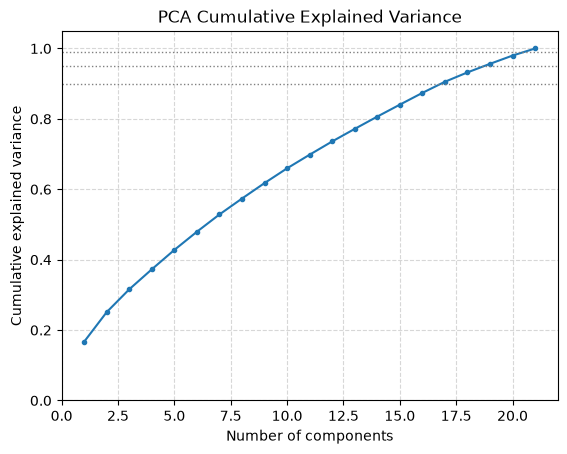

In [ ]:
# PCA : imputation median + stand
mlw.plot_pca_explained_variance(X_train)
for threshold in (0.90, 0.95, 0.99):
    plt.axhline(threshold, color="grey", linestyle=":", linewidth=1)
plt.show()

# PCA ne réduit aucune dimension casiment : on utilise pas.
PCA_COMPONENTS = None

**Commentaires.** La courbe est casi linéaire. On a besoin de 19 features sur 21 pour garder 95 % de la variance. Donc la PCA est pas utile (on utilisera pas ici).

### 4.2 Feature selection

Rank the features, then choose the selection method and the number of features to keep.

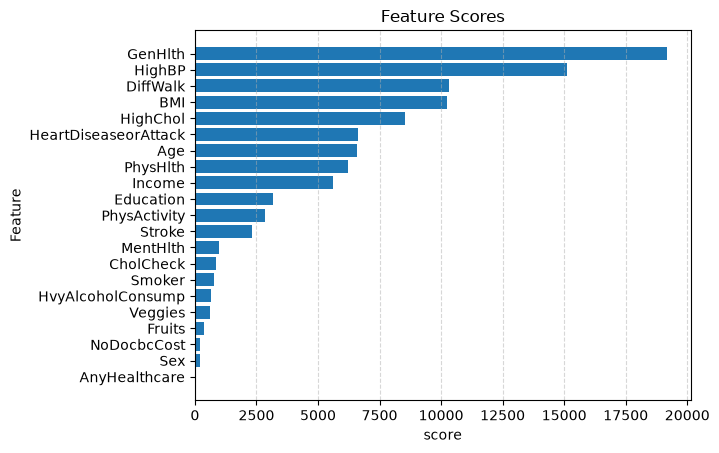

,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",15
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...002260FA79580>


In [ ]:
# Score F (ANOVA) de chaque variable, calculé sur le train uniquement.
scores = mlw.compute_feature_scores(X_train, y_train, method="f_classif")
mlw.plot_feature_scores(scores)
plt.show()

# On garde les 15 meilleures variables.
# On a testé (15 est le meilleur) : ROC AUC de 0,820 avec 15 variables contre 0,823 avec les 21.
SELECTION_METHOD = "kbest"
N_FEATURES = 15
selector = mlw.build_feature_selector(
    SELECTION_METHOD, n_features=N_FEATURES, random_state=RANDOM_STATE
)
selector

**Commentaires.** La santé générale (`GenHlth`), l'hypertension, les difficultés à marcher, l'IMC, le cholestérol, les maladies cardiaques et l'âge sont les variables les plus discriminantes (logique, c'est les risques connus du diabéte). On garde que les 15 meilleures variables : ça ne coûte que 0,003 de ROC AUC (0,820 contre 0,823) et simplifie le modèle.

### 4.3 Models and pipelines

La précision moyenne (AP) est le critère de sélection. Elle évalue le classement des cas positifs rares à différents seuils. Le ROC AUC prolonge la comparaison de la section 4.2. La précision et le rappel décrivent les décisions au seuil par défaut.

In [14]:
SCORING = "average_precision"
pipelines = {
    name: mlw.build_pipeline(model, impute_strategy=IMPUTE_STRATEGY, selector=selector,
                             pca_components=PCA_COMPONENTS, random_state=RANDOM_STATE)
    for name, model in mlw.get_models(random_state=RANDOM_STATE).items()
}

### 4.4 Cross-validation and hyperparameter tuning

La régression logistique fournit une référence additive. Un arbre peut capter des interactions par quelques règles, et le boosting combine plusieurs petits arbres. Les trois pipelines réapprennent les transformations et la sélection des variables dans chacun des cinq plis d’entraînement. Pour chaque complexité, on compare aussi des poids uniformes et des poids équilibrés.

In [15]:
cv = mlw.build_cv_splitter(random_state=RANDOM_STATE)
cv_table, fitted_models = mlw.fit_candidates(
    pipelines, X_train, y_train, scoring=SCORING, cv=cv, compare_weights=True,
)
winner = cv_table.iloc[0]["model"]
display(cv_table.round(4))
print("Selected on training data:", winner)

,model,settings,mean_score,fold_sd,precision,recall
0,Boosting,"class_weight=balanced, max_leaf_nodes=31",0.4303,0.0071,0.3052,0.7936
1,Boosting,"class_weight=None, max_leaf_nodes=31",0.4297,0.0070,0.5821,0.1532
2,Boosting,"class_weight=balanced, max_leaf_nodes=7",0.4278,0.0059,0.3038,0.7939
3,Boosting,"class_weight=None, max_leaf_nodes=7",0.4277,0.0062,0.5694,0.1621
4,Tree,"class_weight=None, max_depth=8",0.4043,0.0058,0.5597,0.1318
5,Logistic,"C=0.1, class_weight=None",0.4031,0.0040,0.5362,0.1513
6,Logistic,"C=1.0, class_weight=None",0.4031,0.0040,0.5360,0.1514
7,Tree,"class_weight=balanced, max_depth=8",0.4031,0.0052,0.2980,0.7786
8,Logistic,"C=0.1, class_weight=balanced",0.4015,0.0037,0.3108,0.7644
9,Logistic,"C=1.0, class_weight=balanced",0.4015,0.0037,0.3108,0.7644


Selected on training data: Boosting


**Commentaire :** À 31 feuilles maximales, le boosting atteint une AP moyenne de 0,4303 avec pondération équilibrée et de 0,4297 avec pondération uniforme. Cet écart est faible devant la dispersion entre plis. Au seuil par défaut, le rappel passe pourtant de 15,3 % à 79,4 % : la pondération modifie surtout la décision. Le meilleur réglage de l’arbre seul atteint 0,4043.

### 4.5 Final training

La recherche réajuste automatiquement le meilleur pipeline de chaque famille sur tout l’entraînement. La référence majoritaire sert à mesurer le gain apporté par les variables.

In [16]:
fitted_models["Majority"] = mlw.majority_baseline(X_train, y_train)
features = mlw.get_selected_features(fitted_models[winner], X_train.columns)
print(f"{len(features)} selected features:", ", ".join(features))

15 selected features: HighBP, HighChol, CholCheck, BMI, Smoker, Stroke, HeartDiseaseorAttack, PhysActivity, GenHlth, MentHlth, PhysHlth, DiffWalk, Age, Education, Income


## 5. Validate the models

Performance of the final models on the test set, which they have never seen.

### 5.1 Metrics

One row per model, one column per metric.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
Logistic,0.8620,0.5641,0.5164,0.1511,0.2338,0.8167,0.3911
Tree,0.8633,0.5622,0.5347,0.1449,0.2280,0.8146,0.3989
Boosting,0.7178,0.7474,0.3030,0.7885,0.4378,0.8239,0.4196
Majority,0.8607,0.5000,0.0000,0.0000,0.0000,0.5000,0.1393


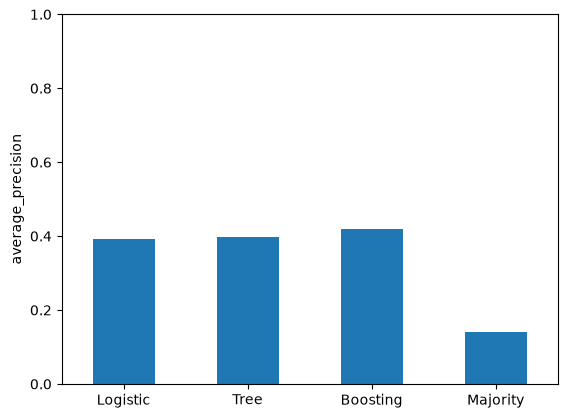

In [17]:
results = mlw.compare_models(fitted_models, X_test, y_test)
counts = ["TN", "FP", "FN", "TP"]
display(results.drop(columns=counts).round(4))
mlw.plot_model_comparison(results, metric=SCORING)
plt.show()

**Commentaire :** Le boosting retenu en validation obtient une AP de 0,420 sur le test, contre 0,399 pour l’arbre seul, 0,391 pour la régression et 0,139 pour le score constant. Son exactitude de 71,8 % doit se lire avec son rappel : la référence atteint 86,1 % d’exactitude en classant tous les répondants négatifs.

### 5.2 Confusion matrices

Kinds of errors made by each model.

,TN,FP,FN,TP
Logistic,42667,1000,6001,1068
Tree,42776,891,6045,1024
Boosting,30845,12822,1495,5574
Majority,43667,0,7069,0


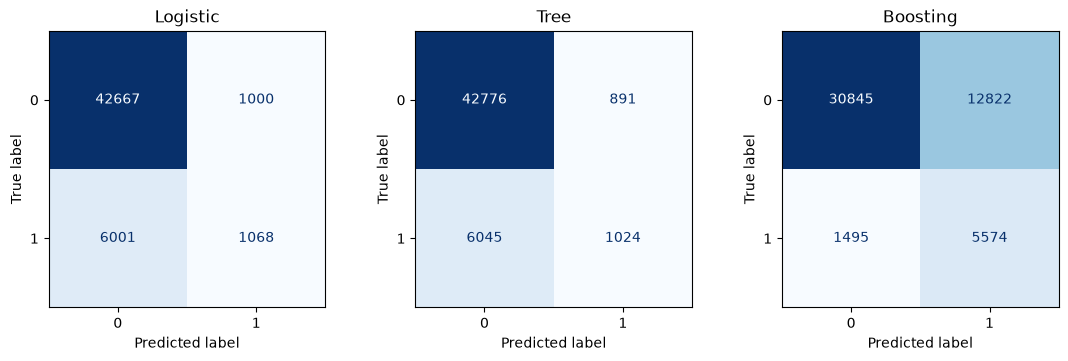

In [18]:
display(results[counts].astype(int))
fig, axes = plt.subplots(1, len(pipelines), figsize=(11, 3.5), layout="constrained")
for ax, name in zip(axes, pipelines):
    mlw.plot_confusion_matrix(fitted_models[name], X_test, y_test, ax=ax)
    ax.set_title(name)
plt.show()

**Commentaire :** Au seuil par défaut, le boosting retrouve 5 574 des 7 069 cas positifs et en manque 1 495. Il déclenche aussi 12 822 fausses alertes. Une précision de 30,3 % correspond ici à environ deux fausses alertes pour chaque cas positif retrouvé.

### 5.3 ROC and precision-recall curves

Behaviour of each model over all decision thresholds.

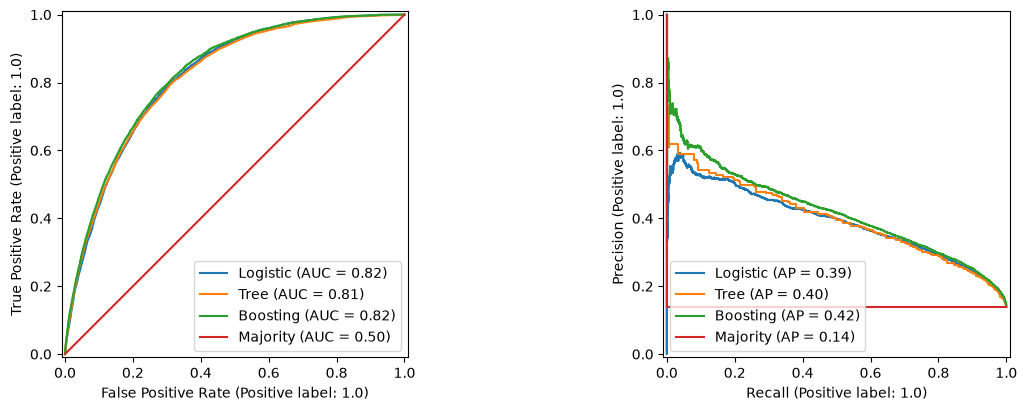

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
mlw.plot_roc_curves(fitted_models, X_test, y_test, ax=axes[0])
mlw.plot_precision_recall_curves(fitted_models, X_test, y_test, ax=axes[1])
plt.show()

**Commentaire :** Le ROC AUC de 0,824 traduit une capacité de classement. L’AP de 0,420 replace cette performance dans une enquête où 13,9 % des étiquettes sont positives. Le volume d’alertes dépend encore du seuil choisi et de la fréquence des cas dans la population visée.

## 6. Discussion and conclusion

Pour classer les répondants selon la cible déclarée, je retiens le boosting pondéré sur les 15 variables sélectionnées. Il arrive en tête en validation puis sur le test. Pour décider qui rappeler, il faudrait préciser la capacité de suivi et le coût des cas manqués, puis choisir le seuil sur des données de validation.

Les réponses de cette enquête sont contemporaines et en partie autodéclarées. Le résultat décrit une association dans BRFSS 2015. Prédire un diagnostic futur demanderait un suivi longitudinal et une évaluation dans une autre population.

## 7. AI usage statement

Codex a aidé à compléter les sections 4.3 à 6 et les fonctions et tests correspondants. Les interprétations ont été vérifiées à partir des sorties de cette expérience. Voir le [README](../README.md).